<a href="https://colab.research.google.com/github/Xrash09/CSA-AI-ML/blob/main/data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1-Data Understanding:

In [34]:
import pandas as pd
import numpy as np

In [35]:
df = pd.read_csv(r"/content/PSComp.csv", comment="#")
print(df.shape)

(6451, 34)


In [36]:
pd.set_option("display.max_columns", None)
df.head()
df.dtypes

,0
loc_rowid,int64
pl_name,object
sy_snum,int64
sy_pnum,int64
discoverymethod,object
disc_year,int64
disc_facility,object
pl_controv_flag,int64
pl_orbper,float64
pl_orbsmax,float64


In [37]:
missing_pct = df.isna().mean()*100
missing_pct = missing_pct.sort_values(ascending=False)
print(missing_pct)

st_spectype        62.641451
pl_orbeccen        16.555573
st_metratio        11.099054
st_met             10.835529
pl_insol            9.238878
pl_eqt              8.370795
pl_orbsmax          7.673229
sy_gaiamag          5.549527
pl_orbper           5.487521
st_logg             5.223996
st_rad              5.146489
sy_vmag             4.851961
st_teff             4.758952
sy_kmag             4.634940
pl_radj             0.775074
pl_rade             0.775074
pl_bmasse           0.465044
pl_bmassj           0.465044
sy_dist             0.434041
st_mass             0.139513
pl_name             0.000000
loc_rowid           0.000000
disc_year           0.000000
disc_facility       0.000000
pl_controv_flag     0.000000
sy_pnum             0.000000
pl_bmassprov        0.000000
discoverymethod     0.000000
sy_snum             0.000000
ttv_flag            0.000000
dec                 0.000000
decstr              0.000000
ra                  0.000000
rastr               0.000000
dtype: float64

In [38]:
df_t = df[df["pl_eqt"].notna()].copy()
print(df_t.shape)

missing_t = (df_t.isna().mean() * 100).sort_values(ascending=False)
print(missing_t)

(5911, 34)
st_spectype        61.191000
pl_orbeccen        10.082896
st_metratio         6.208763
st_met              5.921164
pl_orbsmax          4.483167
pl_orbper           1.184233
pl_insol            1.048892
sy_gaiamag          0.998139
pl_radj             0.659787
pl_rade             0.659787
sy_vmag             0.456776
pl_bmassj           0.439858
pl_bmasse           0.439858
st_logg             0.439858
sy_dist             0.372187
sy_kmag             0.321435
st_rad              0.287599
st_teff             0.186094
st_mass             0.118423
loc_rowid           0.000000
pl_name             0.000000
sy_pnum             0.000000
disc_year           0.000000
discoverymethod     0.000000
pl_controv_flag     0.000000
disc_facility       0.000000
pl_eqt              0.000000
pl_bmassprov        0.000000
sy_snum             0.000000
ttv_flag            0.000000
dec                 0.000000
decstr              0.000000
ra                  0.000000
rastr               0.000000
dty

In [39]:
feats =["pl_eqt", "pl_rade", "pl_bmasse", "pl_orbper", "pl_orbsmax", "st_teff", "st_rad", "st_mass", "sy_dist"]
df_t[feats].describe()

,pl_eqt,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,st_teff,st_rad,st_mass,sy_dist
count,5911.000000,5872.000000,5885.000000,5.841000e+03,5646.000000,5900.000000,5894.000000,5904.000000,5889.000000
mean,836.377171,5.697182,376.325627,7.296597e+04,12.442723,5356.067856,1.495536,0.958641,481.111488
std,495.749851,5.395723,1091.023914,5.262373e+06,248.763535,1245.987376,3.893025,0.374539,487.231518
min,1.480000,0.309800,0.037400,1.768913e-01,0.005000,415.000000,0.011500,0.013100,1.301190
25%,486.185000,1.820000,4.200000,4.301219e+00,0.051000,4899.750000,0.770000,0.799000,89.637000
50%,758.000000,2.790000,8.910000,1.068758e+01,0.095340,5549.000000,0.957000,0.950000,330.916000
75%,1095.000000,11.309881,169.000000,3.806000e+01,0.240528,5904.000000,1.255734,1.100000,760.708000
max,7777.780000,87.205870,12651.500000,4.020000e+08,12000.000000,40000.000000,88.475000,9.100000,6890.000000


In [40]:
#can a

# 2-Exploratory Data Analysis

### 2a-Distribution of Temperature(target)

<Axes: title={'center': 'Distribution of Equilibrium Temperature'}, ylabel='Frequency'>

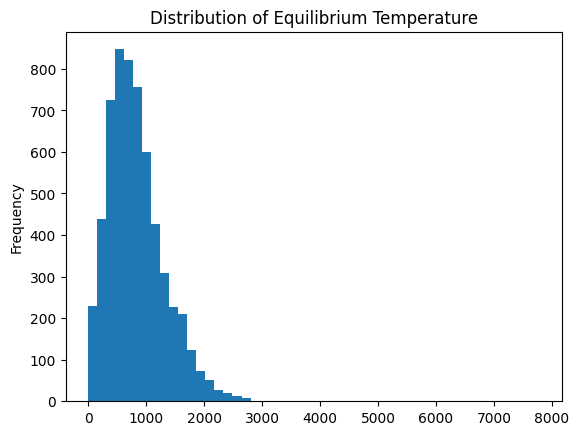

In [41]:
df_t["pl_eqt"].plot(kind="hist" , bins = 50 , title= "Distribution of Equilibrium Temperature")

In [42]:
#calculating mean and median
eqt_mean = np.mean(df_t["pl_eqt"])
eqt_median = np.median(df_t["pl_eqt"])

print(f"For equlibrium temperature, mean: {eqt_mean:.1f} K and median: {eqt_median} K \n")

#finding hottest planet
print(df_t.nlargest(1, "pl_eqt")[["pl_name", "pl_eqt"]])

For equlibrium temperature, mean: 836.4 K and median: 758.0 K 

       pl_name   pl_eqt
2157  KOI-55 b  7777.78


'pl_eqt' is right skewed: the middle 50% percent of planets lie between about 500K and 1100K
(median=758K, mean=836.4K) , with the hottest planet being 'KOI-55 b' with a temperature of 7777.78K.


### 2b- Skewness of Orbital Period

<Axes: title={'center': 'Orbital Period'}, ylabel='Frequency'>

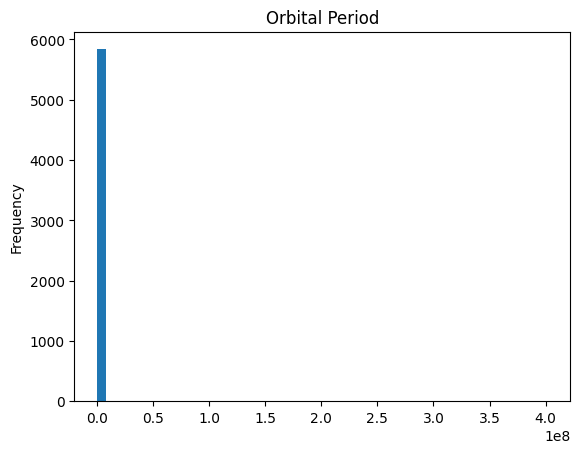

In [43]:
df_t["pl_orbper"].plot(kind="hist", bins=50, title="Orbital Period")

The axis in this graph of raw data runs 4*10^8 days because of few extreme values, so every other planet is squeezed into one bin and the shape is invisible. The most extreme planet is COCONUTS-2b.

<Axes: title={'center': 'Orbital Period(log10)'}, ylabel='Frequency'>

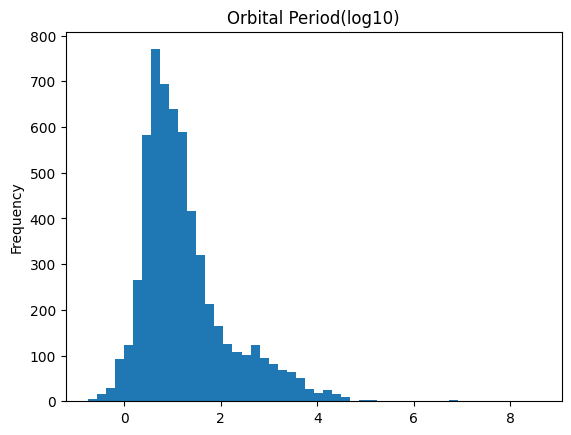

In [44]:
np.log10(df_t["pl_orbper"]).plot(kind ="hist" , bins =50 , title="Orbital Period(log10)")

This graph shows the real shape as its ploted with log10 of orbital periods. It's right skewed as well.

Hence, we conclude that we can use log to show real distribution of data for data with skewed columns

###2c - Missing values in selected features

<Axes: title={'center': '% Missing Per Feature'}>

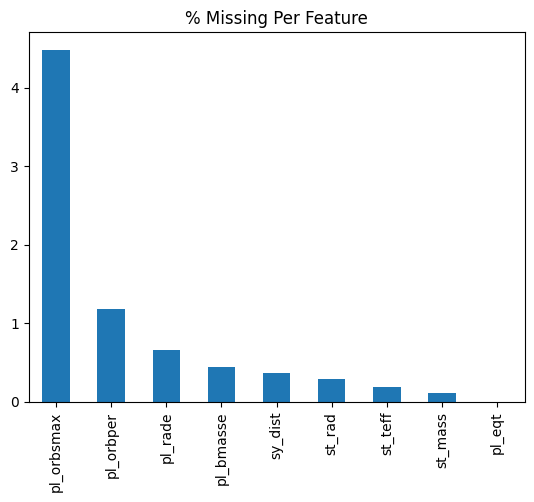

In [45]:
missing_t = (df_t[feats].isna().mean() *100).sort_values(ascending=False)
missing_t.plot(kind='bar', title ="% Missing Per Feature")

In [46]:
print(df_t[feats].shape, df_t[feats].dropna().shape)

(5911, 9) (5493, 9)


###2d -Distance vs Equilibrium Temperature

<Axes: title={'center': 'Distancs v/s Temperature'}, xlabel='pl_orbsmax', ylabel='pl_eqt'>

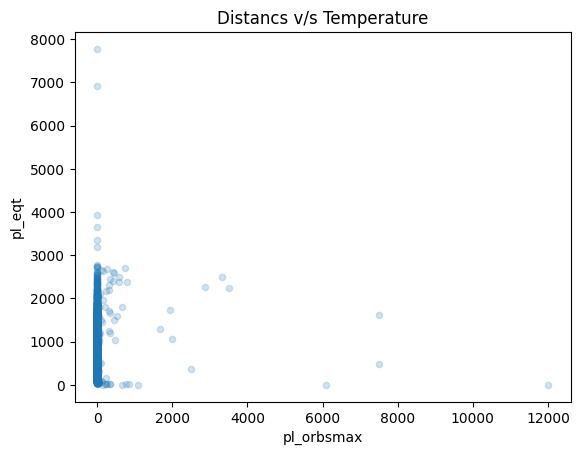

In [47]:
df_t.plot(kind="scatter", x= "pl_orbsmax", y= "pl_eqt", alpha = 0.2, title="Distancs v/s Temperature")

This graph plots the raw data, and its stacked in a column, while a few lie beyond 1000au . Temperature spans 0-3000K mostly.

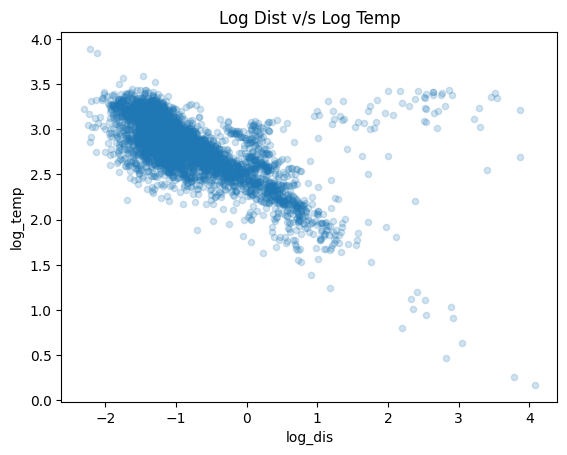

In [48]:
plot_df = pd.DataFrame({
    "log_dis": np.log10(df_t["pl_orbsmax"]),
    "log_temp": np.log10(df_t["pl_eqt"])})
plot_df.plot(kind="scatter", x="log_dis", y ="log_temp" ,alpha =0.2 , title="Log Dist v/s Log Temp")

d = plot_df.dropna()
#do we add slope and intercept?

This is the graph with the log10 values plotted , and it the log10 values are more valuable , planets beyond 10au scatter awya from band, including some that are near 0K and some that are hot.

###2e - Stellar Temperature v/s Equilibrium Temperature

<Axes: title={'center': 'Stellar Temp v/s Equilibrium Temp'}, xlabel='st_teff', ylabel='pl_eqt'>

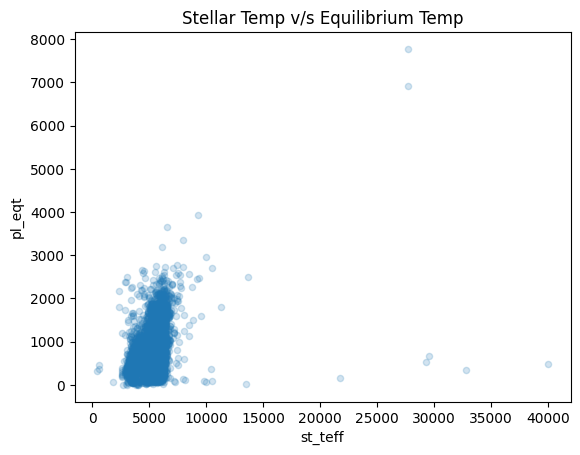

In [50]:
df_t.plot(kind ="scatter", x="st_teff", y ="pl_eqt", alpha = 0.2, title="Stellar Temp v/s Equilibrium Temp")

Hotter stars have more hotter planets , but cloud is wide,stellar temperature of 5000K can have planet temperature from 0 to 2500K.